# 04 — Yolculuk Süresi Tahmini: PySpark MLlib vs scikit-learn (Öğrenci 4)

**Soru:** Aynı veri, aynı özellikler ve aynı hiperparametrelerle eğitildiğinde dağıtık (PySpark MLlib) ve klasik (scikit-learn) yaklaşım doğruluk, süre ve bellek açısından nasıl ayrışır? Veri büyüdükçe bu tablo nasıl değişir?

| | |
|---|---|
| Veri | `data/clean` — 17.210.961 temiz kayıt → 100K / 1M / 5M örneklem (S1'in xxhash64 anahtarı, iç içe) |
| Hedef | `trip_duration_min` ∈ (1, 180] dk |
| Modeller | OLS (`LinearRegression`) ve gradyan artırma (Spark `GBTRegressor` / sklearn `HistGradientBoostingRegressor`) |
| Adillik | Aynı satırlar, aynı train/test ayrımı, aynı özellikler (bölge dahil), aynı hiperparametreler; her ölçüm ayrı süreçte, bellek = süreç ağacının (JVM dahil) tepe RSS'i |

Deneyin tamamı `python -m src.ml_duration` ile çalışır (~10 dk). Bu notebook kayıtlı sonuçları yorumlar ve adilliği 100K örneklemde canlı doğrular.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src import ml_duration as ml
pd.set_option("display.width", 160)
print("Sayısal özellikler:", ml.NUMERIC_FEATURES)
print("Bölge kolonları   :", ml.LOCATION_COLS, "→", ml.CATEGORICAL_FEATURES, f"({ml.N_LOCATION_CODES} kod)")
print(f"GBT: {ml.GBT_MAX_ITER} ağaç, derinlik {ml.GBT_MAX_DEPTH}, öğrenme oranı {ml.GBT_LEARNING_RATE}, yaprakta ≥{ml.GBT_MIN_LEAF}")

Sayısal özellikler: ['trip_distance', 'pickup_hour', 'pickup_dow', 'extra', 'mta_tax', 'tolls_amount', 'improvement_surcharge', 'cbd_congestion_fee']
Bölge kolonları   : ['PULocationID', 'DOLocationID'] → ['PU_code', 'DO_code'] (255 kod)
GBT: 50 ağaç, derinlik 5, öğrenme oranı 0.1, yaprakta ≥20


## 1. Özellik seçimi

| Dışlanan kolon | Neden |
|---|---|
| `fare_amount`, `total_amount`, `tip_amount` | Yolculuk bittikten sonra hesaplanır (sürenin fonksiyonu) → leakage |
| `tpep_dropoff_datetime` | Hedefin kendisinden türetilir → doğrudan leakage |
| `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee` | Flex Fare kayıtlarında (%25,5) kasıtlı null. `dropna()` bu kayıtları silerdi. |

**Sınırlama:** `tolls_amount` ve `cbd_congestion_fee` rota bilgisi taşır ve yolculuk sonunda kesinleşir. Önemleri küçüktür (§4), ancak gerçek zamanlı bir modelde çıkarılmalıdırlar.

**Bölge kodlaması:** Kodlar yalnızca eğitim kümesinden öğrenilir. En sık 254 bölge 0…253 kodunu alır; kalanlar ve görülmeyenler 254 ("diğer") olur. Bu sınır sklearn HistGradientBoosting'in kategorik özellik sınırından (≤ 255) gelir. Aynı kodlar iki çerçeveye de verilir.

## 2. Adillik kontrolü (canlı, 100K örneklem)

Aynı örneklem dosyası iki çerçeveye veriliyor. OLS'nin tek bir çözümü olduğu için iki çerçeve **aynı tahmini** vermeli; vermiyorsa karşılaştırma adil değildir.

In [2]:
from pyspark.sql import functions as F
from src.spark_session import get_spark

sample_dir = ml.SAMPLES_DIR / "100K"
spark = get_spark(app_name="s4-notebook")
sdf = ml.with_nominal_metadata(spark.read.parquet(str(sample_dir)))
train = sdf.filter(F.col(ml.SPLIT_COL)).drop(ml.SPLIT_COL)
test = sdf.filter(~F.col(ml.SPLIT_COL)).drop(ml.SPLIT_COL)
spark_metrics = ml._evaluate(ml._build_pipeline("lr").fit(train).transform(test))

pdf = pd.read_parquet(sample_dir)
for c in ml.CATEGORICAL_FEATURES:
    pdf[c] = pdf[c].astype("int64")
X = pdf[ml.NUMERIC_FEATURES + ml.CATEGORICAL_FEATURES]; y = pdf[ml.TARGET_COL]; m = pdf[ml.SPLIT_COL]
sk_model = ml.build_sklearn_model("lr").fit(X[m], y[m])
sk_metrics = ml.sklearn_metrics(y[~m], sk_model.predict(X[~m]))
spark.stop()

check = pd.DataFrame([spark_metrics, sk_metrics], index=["PySpark", "scikit-learn"]).round(4)
check

,rmse,mae,r2
PySpark,7.2018,4.9090,0.6427
scikit-learn,7.2007,4.9089,0.6428


## 3. Sonuçlar (12 ölçüm)

In [3]:
comparison, importance, pred = ml.load_saved()
cols = ["framework", "model", "size_label", "n_train", "rmse", "mae", "r2", "train_time_s", "predict_time_s", "peak_rss_mb", "peak_jvm_mb"]
comparison[cols]

,framework,model,size_label,n_train,rmse,mae,r2,train_time_s,predict_time_s,peak_rss_mb,peak_jvm_mb
0,PySpark,LinearRegression,100K,79549,7.2018,4.9090,0.6427,3.173,0.435,738.8,646.5
1,PySpark,GBTRegressor,100K,79549,6.0003,3.8298,0.7520,22.550,0.505,1130.7,1038.4
2,scikit-learn,LinearRegression,100K,79549,7.2007,4.9089,0.6428,0.494,0.010,209.9,NaN
3,scikit-learn,HistGradientBoosting,100K,79549,5.7137,3.6866,0.7751,0.203,0.018,212.1,NaN
4,PySpark,LinearRegression,1M,798285,7.1697,4.9238,0.6476,4.963,0.801,1237.8,1145.5
5,PySpark,GBTRegressor,1M,798285,5.5480,3.5866,0.7890,52.524,1.630,2802.6,2710.6
6,scikit-learn,LinearRegression,1M,798285,7.1700,4.9241,0.6475,6.856,0.092,745.9,NaN
7,scikit-learn,HistGradientBoosting,1M,798285,5.5712,3.6106,0.7872,1.129,0.215,553.4,NaN
8,PySpark,LinearRegression,5M,3997515,7.1754,4.9260,0.6473,12.311,2.409,1815.4,1723.0
9,PySpark,GBTRegressor,5M,3997515,5.4810,3.5543,0.7942,197.448,6.008,4160.6,4068.4


In [4]:
# Çerçeveler arası oranlar (aynı model ailesi, aynı boyut)
pairs = {"LinearRegression": ("LinearRegression", "LinearRegression"), "GBT": ("GBTRegressor", "HistGradientBoosting")}
rows = []
for family, (spark_m, sk_m) in pairs.items():
    for size in ml.SAMPLE_LABELS:
        s = comparison[(comparison.framework == "PySpark") & (comparison.model == spark_m) & (comparison.size_label == size)].iloc[0]
        k = comparison[(comparison.framework == "scikit-learn") & (comparison.model == sk_m) & (comparison.size_label == size)].iloc[0]
        rows.append({"aile": family, "boyut": size,
                     "süre oranı Spark/sklearn": round(s.train_time_s / k.train_time_s, 1),
                     "bellek oranı Spark/sklearn": round(s.peak_rss_mb / k.peak_rss_mb, 2),
                     "RMSE farkı (Spark − sklearn)": round(s.rmse - k.rmse, 3)})
pd.DataFrame(rows)

,aile,boyut,süre oranı Spark/sklearn,bellek oranı Spark/sklearn,RMSE farkı (Spark − sklearn)
0,LinearRegression,100K,6.4,3.52,0.001
1,LinearRegression,1M,0.7,1.66,-0.000
2,LinearRegression,5M,0.4,0.59,-0.001
3,GBT,100K,111.1,5.33,0.287
4,GBT,1M,46.5,5.06,-0.023
5,GBT,5M,40.8,1.88,-0.080


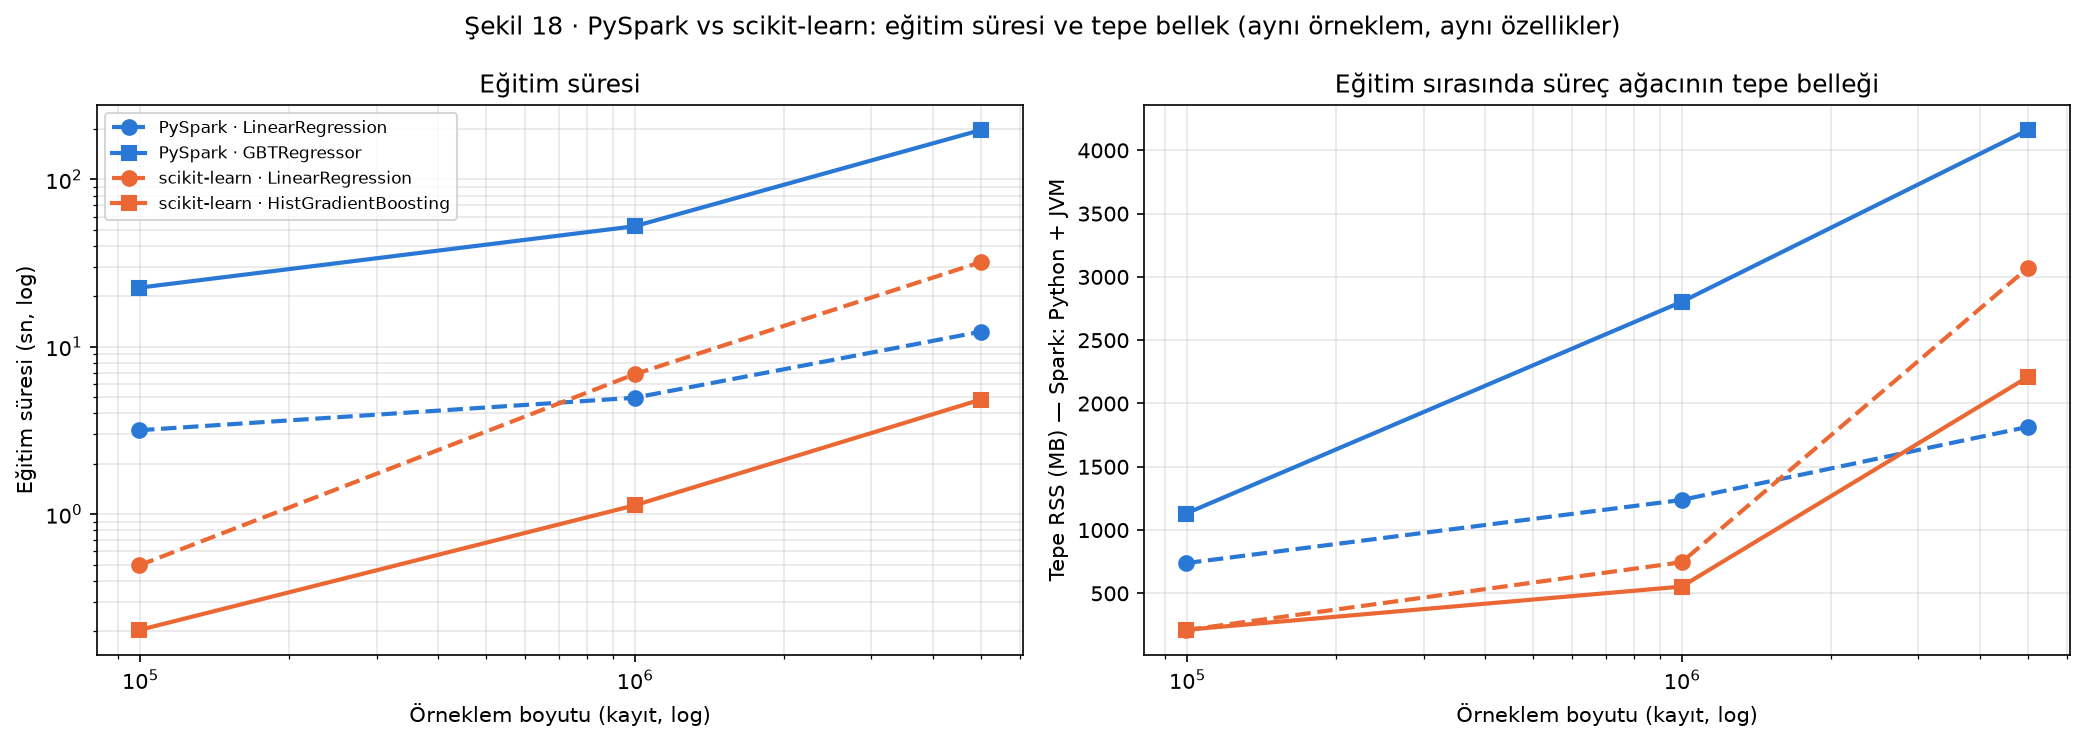

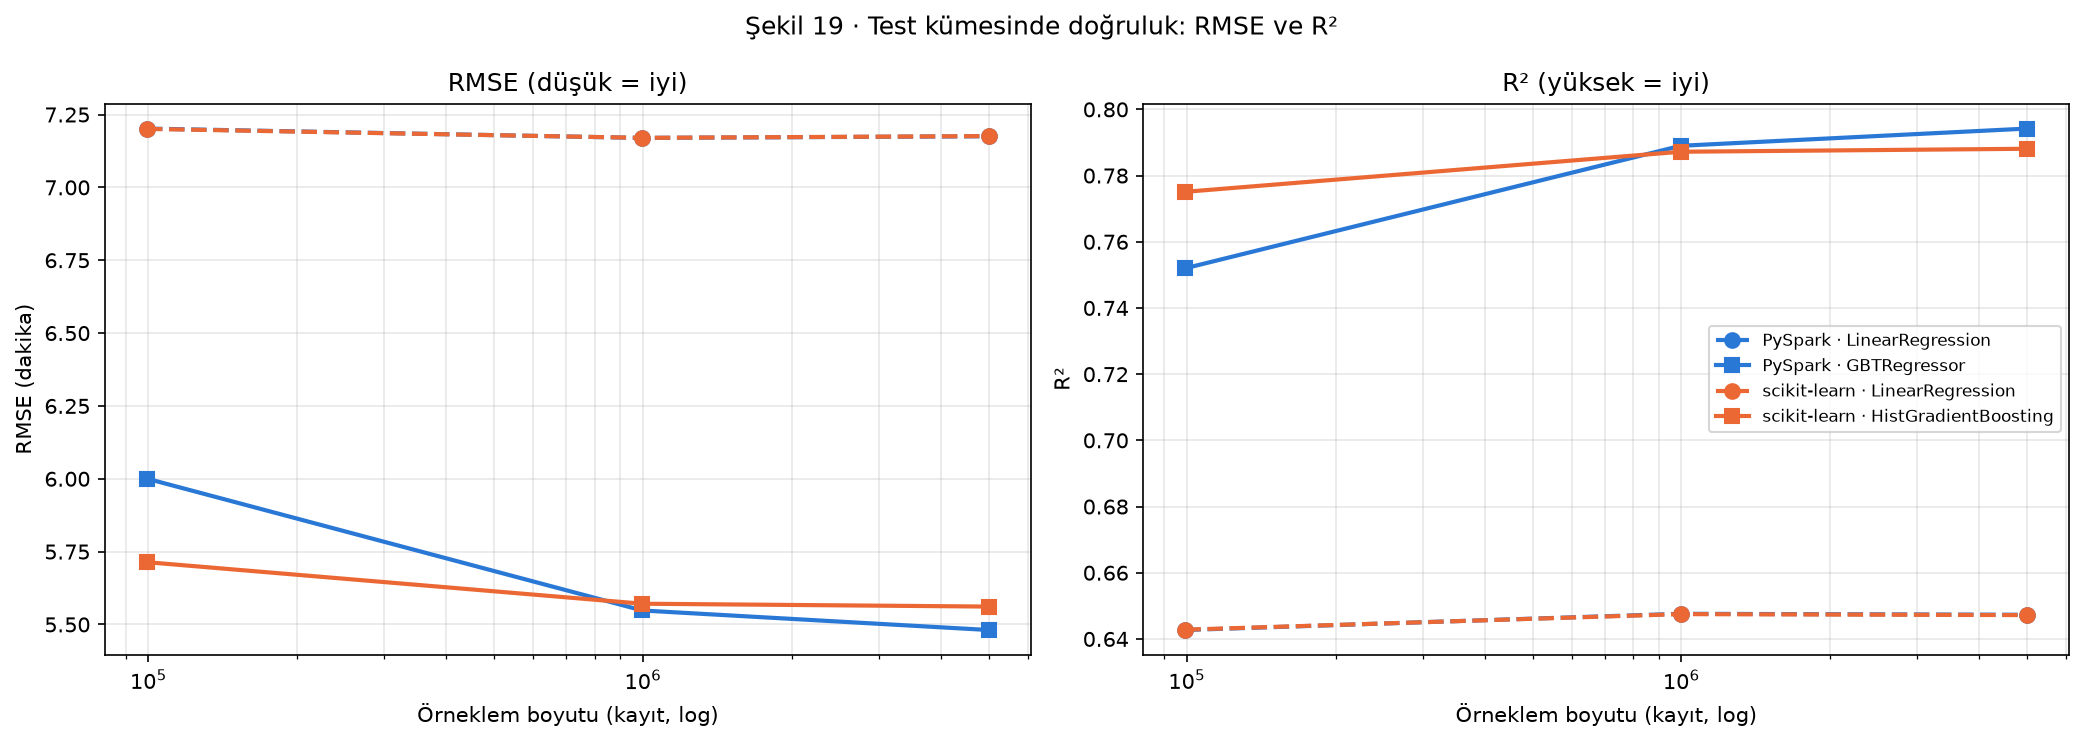

In [5]:
for f in ["18_s4_scalability.png", "19_s4_model_comparison.png"]:
    display(Image(filename=str(ml.FIGURES_DIR / f)))

## 4. Özellik önemi ve tahmin kalitesi (Spark GBT, 1M)

,feature,importance
0,trip_distance,0.465847
1,DOLocationID,0.184305
2,pickup_hour,0.135108
3,PULocationID,0.124800
4,pickup_dow,0.071384
5,cbd_congestion_fee,0.005671
6,tolls_amount,0.005359
7,improvement_surcharge,0.005297
8,extra,0.002056
9,mta_tax,0.000172


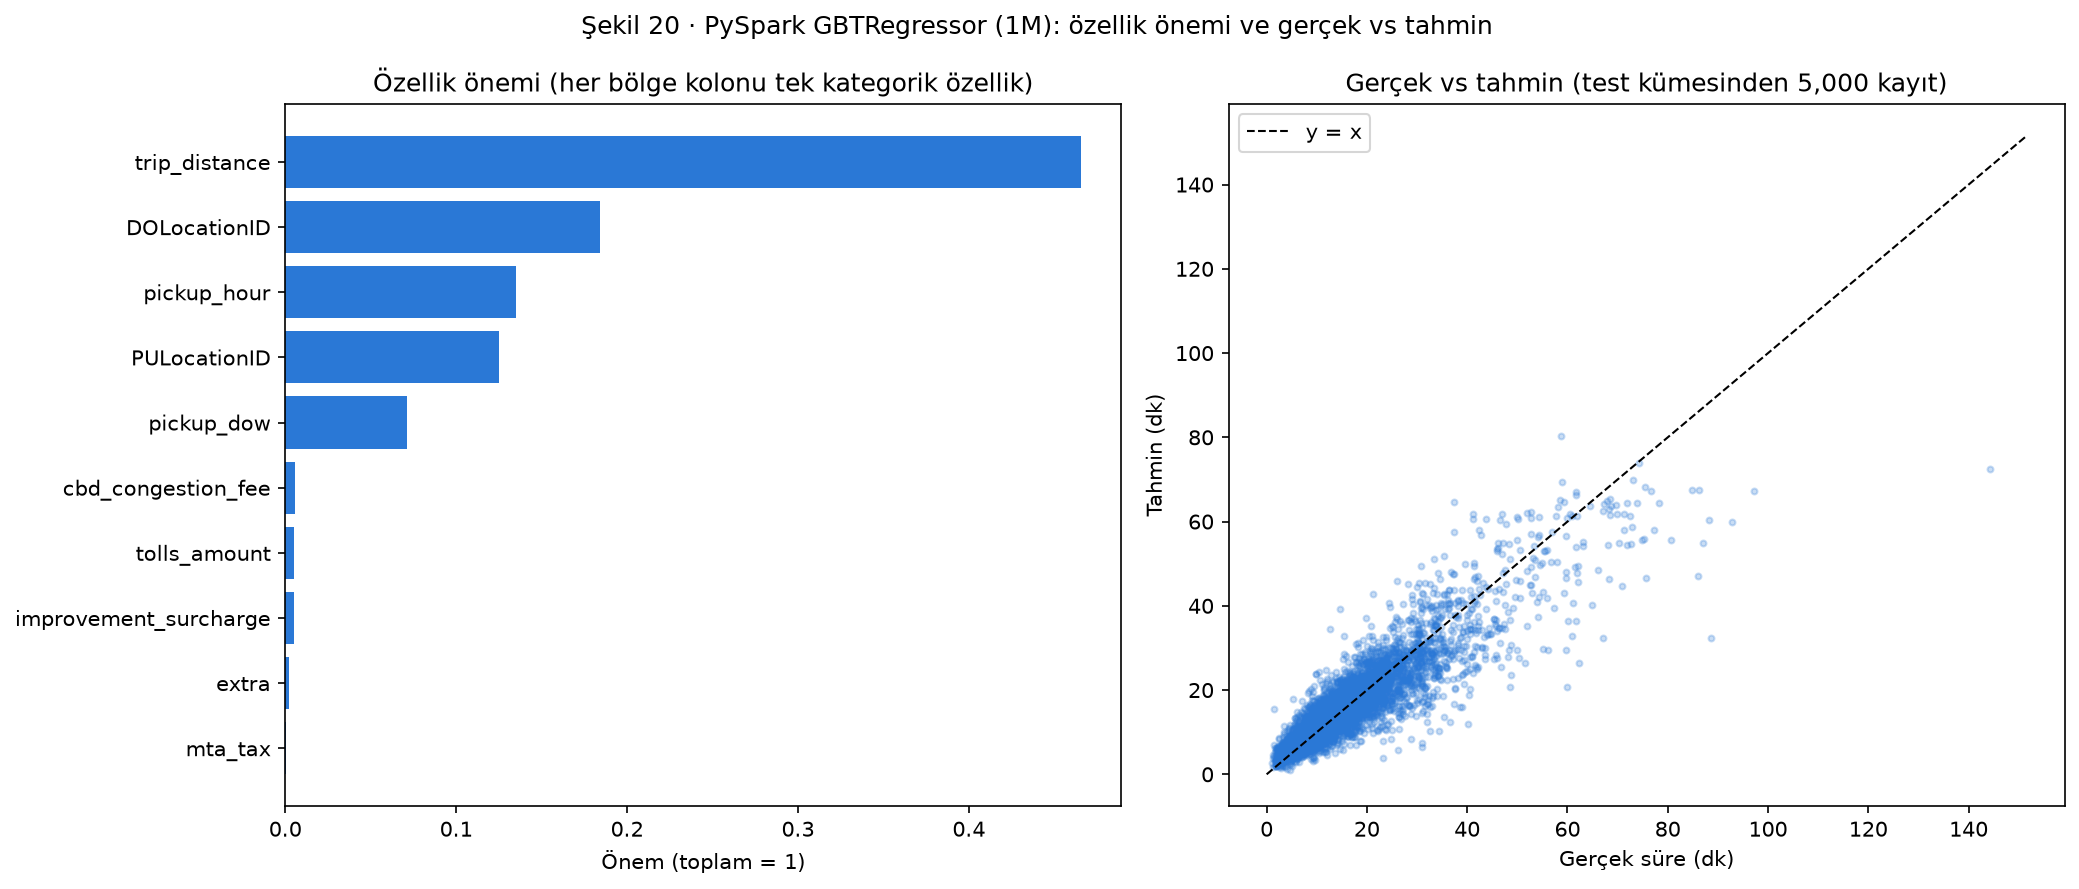

In [6]:
display(importance)
display(Image(filename=str(ml.FIGURES_DIR / "20_s4_feature_actual_pred.png")))

## 5. Yorum — neden böyle?

- **Adillik:** OLS iki çerçevede aynı sonucu veriyor (§2 ve üç boyutta RMSE farkı ≤ 0,001). Kalan farklar algoritma uygulamasından geliyor.
- **GBT, OLS'den ~%23 daha iyi.** Süre mesafeyle doğrusal artmıyor. Bölge ve saat etkileşimleri (Manhattan içi yoğun saat, havalimanı otoyolu) ağaç bölmeleriyle yakalanıyor. Bölgelerin toplam önemi (~0,31), saat ve günün toplamından (~0,21) büyük.
- **Veri büyüdükçe yalnızca esnek model iyileşiyor.** OLS'nin R²'si 100K'dan 5M'e sabit (~0,65); hatası yanlılıktan (bias) geliyor. GBT 0,75'ten 0,79'a çıkıyor, çünkü nadir bölgeler ancak büyük örneklemde kendi bölmelerini alabiliyor.
- **Tek makinede sklearn GBT çok daha hızlı** (100K'da ~110×, 5M'de ~40×). Spark her ağaç seviyesini ayrı bir iş olarak zamanlıyor, histogramları shuffle ile birleştiriyor ve veriyi JVM ile Python arasında serileştiriyor. Bu sabit maliyetin göreli payı veri büyüdükçe azalıyor.
- **Doğrusal modelde sıra 1M'de tersine dönüyor.** Spark normal denklemi (XᵀX) tek geçişte ve paralel kuruyor. sklearn ise seyrek matriste tek çekirdekli iteratif `lsqr` çözücüsü kullanıyor. Algoritma seçimi motor seçiminden daha belirleyici.
- **Bellek:** Spark'ın JVM tabanı (~0,5 GB) var ve GBT 5M'de 4,2 GB'a çıkıyor. sklearn belleği kayıtla doğrusal artıyor (~0,4–0,6 KB/kayıt). sklearn LinearRegression 5M'de Spark'tan fazla bellek kullanıyor (seyrek matris ve çözücü kopyaları). Doğrusal ekstrapolasyonla bu makinede ~55–80M kayıtta RAM dolar.

**Araştırma sorusuna katkı:** RAM'e sığan veride (burada ≤ 5M) klasik yaklaşım yetersiz kalmıyor; aksine hem daha hızlı hem daha az bellek kullanıyor. Spark'ın getirisi verinin tek makinenin belleğini aştığı veya küme gerektiği noktada başlar.

**Sınırlamalar:** tek makine (`local[*]`); hiperparametre araması yok; iki GBT uygulaması birebir aynı değil (başlangıç tahmini ve bin sınırları farklı).